# Will an online shopping session end in a purchase?

A retailer's analytics team could use a purchase score to rank sessions for closer funnel analysis. The label is `Revenue`, a Boolean purchase outcome. We use the [UCI Online Shoppers Purchasing Intention dataset](https://doi.org/10.24432/C5F88Q).

The data is a set of session summaries. To score active sessions at a specific time, we would need to retrain and validate with features from that same point in each session.

In [1]:
import os

os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from train import (
    CATEGORICAL, EXCLUDED, FEATURES, HYPERPARAMETERS, NUMERIC, SEED, TARGET,
    load_data, score_holdout, split_data, tune_models,
)

frame = load_data()
X_dev, X_test, y_dev, y_test, groups_dev = split_data(frame)
dev = frame.loc[X_dev.index]
assert set(groups_dev).isdisjoint(pd.util.hash_pandas_object(X_test, index=False))
print(f"Rows: {len(frame):,} total | {len(dev):,} development | {len(X_test):,} held out")

Matplotlib is building the font cache; this may take a moment.


Rows: 12,330 total | 9,864 development | 2,466 held out


## Data preparation and exploration

The development data is used for exploration and model selection. Identical feature profiles stay in the same partition and validation fold. Distinct visitors can have the same logged profile, so repeated profiles stay in the data. We exclude `PageValues` because it uses transaction value, and omit `BounceRates` and `ExitRates` to keep inputs independent of page-level exit analytics.

The model imputes numerical values with the training median and categorical values with the training mode if it encounters missing inputs during training. Integer-coded device, traffic and region fields are categorical and one-hot encoded. The logistic model also standardizes numerical inputs. These transformations are fitted inside each fold.

In [2]:
audit = pd.DataFrame({
    "type": dev.dtypes.astype(str),
    "missing": dev.isna().sum(),
    "distinct": dev.nunique(),
})
display(audit)
print(f"Exact repeat rows in development: {dev.duplicated().sum():,}")
print(f"Repeat model profiles in development: {dev.duplicated(subset=FEATURES).sum():,}")
print(f"Non-finite numeric inputs: {dev[NUMERIC].isin([float('inf'), -float('inf')]).sum().sum()}")
display(dev[NUMERIC].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T.round(2))
display(dev[CATEGORICAL].nunique().rename("distinct categories"))

,type,missing,distinct
Administrative,int64,0,27
Administrative_Duration,float64,0,2843
Informational,int64,0,17
Informational_Duration,float64,0,1062
ProductRelated,int64,0,297
ProductRelated_Duration,float64,0,7807
BounceRates,float64,0,1604
ExitRates,float64,0,3986
PageValues,float64,0,2178
SpecialDay,float64,0,6


Exact repeat rows in development: 100
Repeat model profiles in development: 105
Non-finite numeric inputs: 0


,count,mean,std,min,1%,50%,95%,99%,max
Administrative,9864.0,2.34,3.34,0.0,0.0,1.0,9.00,14.00,27.00
Administrative_Duration,9864.0,81.06,177.74,0.0,0.0,8.0,344.45,826.41,3398.75
Informational,9864.0,0.50,1.28,0.0,0.0,0.0,3.00,6.00,24.00
Informational_Duration,9864.0,33.93,138.72,0.0,0.0,0.0,193.24,703.96,2549.38
ProductRelated,9864.0,31.83,45.25,0.0,1.0,18.0,110.00,224.37,705.00
ProductRelated_Duration,9864.0,1194.27,1960.46,0.0,0.0,593.5,4276.34,8724.96,63973.52
SpecialDay,9864.0,0.06,0.20,0.0,0.0,0.0,0.60,1.00,1.00


Month               10
OperatingSystems     8
Browser             12
Region               9
TrafficType         19
VisitorType          3
Weekend              2
Name: distinct categories, dtype: int64

,sessions,share
Revenue,,
No purchase,8338,0.845
Purchase,1526,0.155


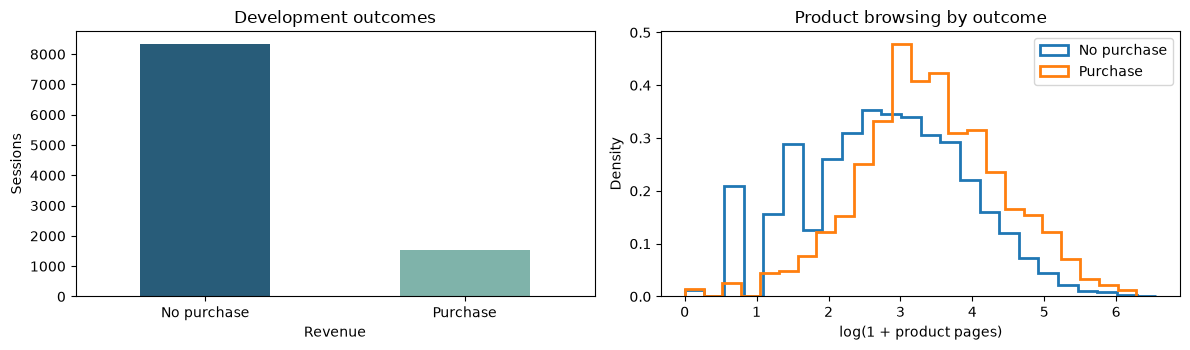

,sessions,purchase_rate
VisitorType,,
Returning_Visitor,8446,13.8%
New_Visitor,1350,25.6%
Other,68,19.1%


,sessions,purchase_rate
Month,,
May,2702,10.8%
Nov,2387,25.4%
Mar,1513,10.6%
Dec,1401,12.3%
Oct,449,21.2%
Sep,355,18.0%
Aug,354,16.9%
Jul,342,15.5%
June,228,9.2%


,sessions,purchase_rate
Weekend,,
False,7585,14.9%
True,2279,17.5%


In [3]:
labels = y_dev.map({0: "No purchase", 1: "Purchase"})
target_counts = labels.value_counts()
display(pd.DataFrame({"sessions": target_counts, "share": (target_counts / len(dev)).round(3)}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
target_counts.plot.bar(ax=axes[0], color=["#285c79", "#7fb3aa"], rot=0)
axes[0].set(title="Development outcomes", ylabel="Sessions")
for outcome, subset in dev.groupby(TARGET):
    axes[1].hist(subset["ProductRelated"].map(lambda n: __import__("math").log1p(n)),
                 bins=24, density=True, histtype="step", linewidth=2,
                 label="Purchase" if outcome else "No purchase")
axes[1].set(title="Product browsing by outcome", xlabel="log(1 + product pages)", ylabel="Density")
axes[1].legend()
plt.tight_layout()
plt.show()

for column in ("VisitorType", "Month", "Weekend"):
    summary = dev.groupby(column)[TARGET].agg(sessions="size", purchase_rate="mean")
    display(summary.sort_values("sessions", ascending=False).style.format({"purchase_rate": "{:.1%}"}))

## Baseline, model comparison and tuning

A prior-only baseline gives every session the same score. Logistic regression gives us a linear baseline on the log-odds scale. The two tree ensembles can capture nonlinear effects and interactions. Three-fold grouped, stratified cross-validation compares hyperparameters on the same folds. We select by mean average precision (AP) because purchases are the minority class and we care about ranking sessions with positive outcomes. ROC AUC is a secondary metric.

In [4]:
display(pd.Series(HYPERPARAMETERS, name="hyperparameter grids"))
name, model, comparison = tune_models(X_dev, y_dev, groups_dev)
display(pd.DataFrame(comparison).round(4))
print(f"Selected by development average precision: {name}")

Logistic regression            {'model__C': [0.01, 0.1, 1, 10], 'model__class...
Random forest                  {'model__max_depth': [6, 12, None], 'model__mi...
Histogram gradient boosting    {'model__learning_rate': [0.05, 0.1], 'model__...
Name: hyperparameter grids, dtype: object

,model,cv_ap,cv_ap_std,cv_roc_auc,params
0,Random forest,0.3709,0.0222,0.7663,"{'model__max_depth': None, 'model__min_samples..."
1,Histogram gradient boosting,0.3581,0.0177,0.7669,"{'model__learning_rate': 0.05, 'model__max_lea..."
2,Logistic regression,0.2999,0.0172,0.7227,"{'model__C': 0.01, 'model__class_weight': 'bal..."
3,Prior baseline,0.1547,0.0001,0.5000,{}


Selected by development average precision: Random forest


## Held-out performance

The selected pipeline is already refitted on all development data. Use the test partition to estimate ranking performance and inspect an illustrative decision threshold. The matrix uses rows for actual outcomes and columns for predicted outcomes. A threshold for a real workflow would depend on its review capacity and the cost of mistakes.

average_precision                        0.321225
roc_auc                                  0.749975
brier_score                               0.11775
positive_rate                            0.154907
confusion_matrix_at_0_5    [[2070, 14], [374, 8]]
n                                            2466
Name: holdout, dtype: object

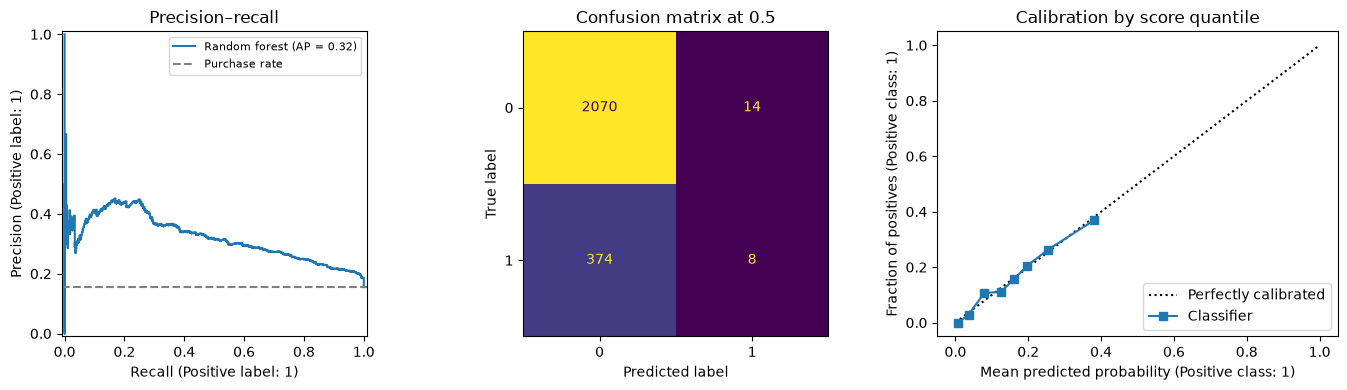

In [5]:
report = score_holdout(model, X_test, y_test)
display(pd.Series(report, name="holdout"))
probs = model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
PrecisionRecallDisplay.from_predictions(y_test, probs, ax=axes[0], name=name)
axes[0].axhline(y_test.mean(), linestyle="--", color="gray", label="Purchase rate")
axes[0].set_title("Precision–recall")
axes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(y_test, probs >= 0.5, ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix at 0.5")
CalibrationDisplay.from_predictions(y_test, probs, n_bins=8, strategy="quantile", ax=axes[2])
axes[2].set_title("Calibration by score quantile")
plt.tight_layout()
plt.show()

## Feature importance

Permutation importance measures how much the fitted model's held-out AP drops when one input is shuffled. We shuffle original fields before preprocessing, so each categorical field is assessed as a whole. Correlated features can share importance, and these measurements describe the model’s reliance on each field.

,mean_ap_drop,std_ap_drop
Month,0.0437,0.0109
VisitorType,0.0427,0.0048
ProductRelated_Duration,0.0407,0.0060
TrafficType,0.0123,0.0042
ProductRelated,0.0116,0.0055
Administrative_Duration,0.0084,0.0050
OperatingSystems,0.0078,0.0037
Administrative,0.0039,0.0047
Informational_Duration,0.0032,0.0018
SpecialDay,0.0025,0.0015


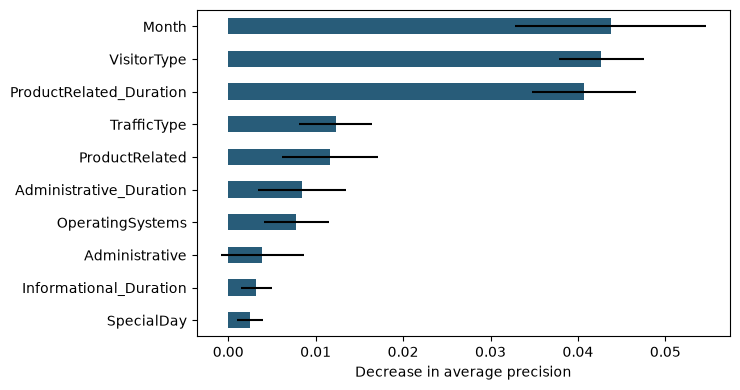

In [6]:
importance = permutation_importance(
    model, X_test, y_test, scoring="average_precision", n_repeats=5,
    random_state=SEED, n_jobs=1,
)
ranking = pd.DataFrame({
    "mean_ap_drop": importance.importances_mean,
    "std_ap_drop": importance.importances_std,
}, index=X_test.columns).sort_values("mean_ap_drop", ascending=False)
display(ranking.round(4))
top = ranking.head(10).sort_values("mean_ap_drop")
top["mean_ap_drop"].plot.barh(xerr=top["std_ap_drop"], color="#285c79", figsize=(7.5, 4))
plt.xlabel("Decrease in average precision")
plt.tight_layout()
plt.show()

Month, visitor type and time spent on product pages produced the largest held-out AP drops when shuffled. Month may reflect seasonality or the site's campaign schedule. The grouped random holdout estimates performance on this sample and leaves future-season performance unmeasured. At the illustrative 0.5 cutoff, the model found only 8 of 382 purchases, so the ranking and precision–recall curve are more informative for review.

## Reproduce the service

Run `uv run --locked python train.py` to export the fitted preprocessing and classifier as one artifact. Run `uv run --locked python predict.py` to serve it via FastAPI, or build the Dockerfile to reproduce training and serving from the locked environment. The README includes an example request and deployment steps.